In [4]:
from google.colab import files
uploaded = files.upload()

Saving archive (4).zip to archive (4) (1).zip


In [5]:
!unzip -o "/content/archive (4).zip" -d /content

Archive:  /content/archive (4).zip
  inflating: /content/WA_Fn-UseC_-Telco-Customer-Churn.csv  


In [6]:
import pandas as pd
df=pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()
df.shape
df.columns
df.isnull().sum()
df["Churn"].value_counts()
df.info()
df.isnull().sum().sum()
df["TotalCharges"].dtype


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


dtype('O')

In [7]:
df["TotalCharges"] = df["TotalCharges"].astype(str).str.strip()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print(df["TotalCharges"].isnull().sum())

df.loc[
    df["TotalCharges"].isnull(),
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [8]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print(df["TotalCharges"].isnull().sum())

print(df.shape)
print(df.isnull().sum().sum())
print(df["TotalCharges"].dtype)

0
(7043, 21)
0
float64


In [9]:
print("NUMERICAL COLUMNS:")
print(df.select_dtypes(include=["int64", "float64"]).columns.tolist())

print("\nCATEGORICAL COLUMNS:")
print(df.select_dtypes(include=["object"]).columns.tolist())

NUMERICAL COLUMNS:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

CATEGORICAL COLUMNS:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [10]:


X = df.drop(columns=["Churn"])
y = df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())



X shape: (7043, 20)
y shape: (7043,)

Target values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:

print("Total input features:", len(X.columns))
print("\nAll input feature names:")
print(X.columns.tolist())


In [11]:
print(df.columns.tolist())
print(X.shape)
print(y.shape)

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
(7043, 20)
(7043,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 20)
X_test: (1409, 20)
y_train: (5634,)
y_test: (1409,)


In [13]:
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [14]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Original X_train shape:", X_train.shape)
print("Encoded X_train shape:", X_train_encoded.shape)

print("Original X_test shape:", X_test.shape)
print("Encoded X_test shape:", X_test_encoded.shape)

Original X_train shape: (5634, 20)
Encoded X_train shape: (5634, 5679)
Original X_test shape: (1409, 20)
Encoded X_test shape: (1409, 5679)


In [16]:
print("X_train columns:")
print(X_train.columns.tolist())

print("\nCustomerID present?")
print("customerID" in X_train.columns)

print("\nNumber of categorical columns:")
print(len(categorical_cols))

print("\nCategorical columns:")
print(categorical_cols)

X_train columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

CustomerID present?
True

Number of categorical columns:
16

Categorical columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [17]:
df = df.drop(columns=["customerID"], errors="ignore")

X = df.drop(columns=["Churn"])
y = df["Churn"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5634, 19)
(1409, 19)


In [18]:
print(X_train.columns.tolist())
print("customerID" in X_train.columns)

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
False


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5634, 19)
(1409, 19)


In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_cols)
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded X_train:", X_train_encoded.shape)
print("Encoded X_test:", X_test_encoded.shape)

Encoded X_train: (5634, 45)
Encoded X_test: (1409, 45)


In [21]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_encoded, y_train)

print("Model training completed!")

Model training completed!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [22]:
y_pred = model.predict(X_test_encoded)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']


In [23]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.8048261178140526
Model Accuracy (%): 80.48261178140525


[[923 112]
 [163 211]]


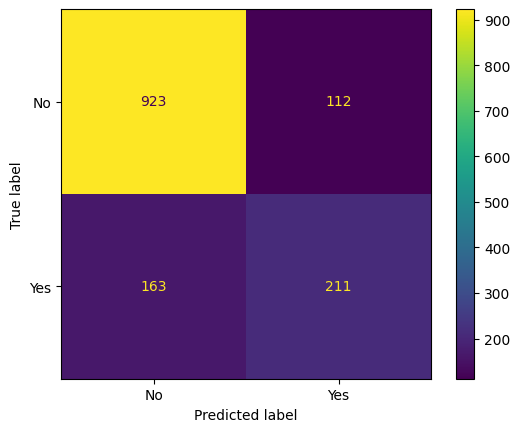

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

display.plot()
plt.show()

In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.65      0.56      0.61       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



In [26]:
#New Model:
from sklearn.linear_model import LogisticRegression

model_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model_balanced.fit(X_train_encoded, y_train)

print("Balanced model training completed!")

Balanced model training completed!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [27]:
from sklearn.linear_model import LogisticRegression

model_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model_balanced.fit(X_train_encoded, y_train)

y_pred_balanced = model_balanced.predict(X_test_encoded)

print(y_pred_balanced[:10])

['No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'Yes']


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [28]:
from sklearn.metrics import classification_report

y_pred_original = model.predict(X_test_encoded)

print("ORIGINAL MODEL")
print(classification_report(y_test, y_pred_original))

print("BALANCED MODEL")
print(classification_report(y_test, y_pred_balanced))

ORIGINAL MODEL
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.65      0.56      0.61       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409

BALANCED MODEL
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.79      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [29]:
print(model_balanced.classes_)

probabilities = model_balanced.predict_proba(X_test_encoded)

print(probabilities[:5])

['No' 'Yes']
[[0.88702941 0.11297059]
 [0.14904283 0.85095717]
 [0.84134963 0.15865037]
 [0.34587823 0.65412177]
 [0.94289353 0.05710647]]


In [30]:
print(model_balanced.classes_)
print(probabilities[:5])

['No' 'Yes']
[[0.88702941 0.11297059]
 [0.14904283 0.85095717]
 [0.84134963 0.15865037]
 [0.34587823 0.65412177]
 [0.94289353 0.05710647]]


In [31]:
yes_index = list(model_balanced.classes_).index("Yes")

churn_probability = probabilities[:, yes_index]

print(churn_probability[:5])

[0.11297059 0.85095717 0.15865037 0.65412177 0.05710647]


In [32]:
import numpy as np

threshold = 0.3

y_pred_30 = np.where(
    churn_probability >= threshold,
    "Yes",
    "No"
)

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_30))

              precision    recall  f1-score   support

          No       0.96      0.56      0.70      1035
         Yes       0.43      0.93      0.59       374

    accuracy                           0.66      1409
   macro avg       0.69      0.74      0.65      1409
weighted avg       0.82      0.66      0.67      1409



[[578 457]
 [ 27 347]]


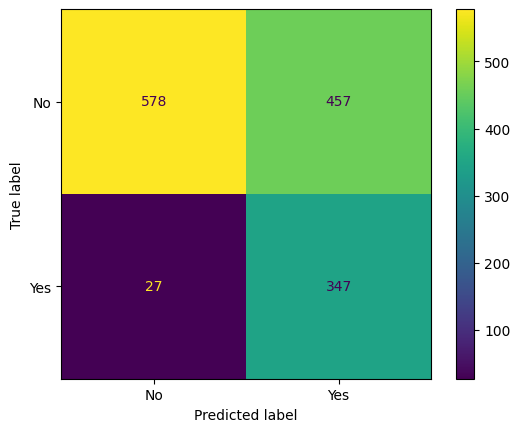

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_30,
    labels=["No", "Yes"]
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot()
plt.show()

In [34]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

#default threshold = 0.5
y_pred_final = model_balanced.predict(X_test_encoded)

print("CUSTOMER CHURN PREDICTION - FINAL RESULTS")
print("-" * 45)

print("Accuracy:", round(accuracy_score(y_test, y_pred_final) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final, labels=["No", "Yes"]))


CUSTOMER CHURN PREDICTION - FINAL RESULTS
---------------------------------------------
Accuracy: 73.67 %

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.79      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Confusion Matrix:
[[744 291]
 [ 80 294]]


In [35]:
print("X_test shape:", X_test.shape)
print("X_test_encoded shape:", X_test_encoded.shape)
print("y_test length:", len(y_test))
print("y_pred_final length:", len(y_pred_final))
print("Model classes:", model_balanced.classes_)


X_test shape: (1409, 19)
X_test_encoded shape: (1409, 45)
y_test length: 1409
y_pred_final length: 1409
Model classes: ['No' 'Yes']


In [36]:
import pandas as pd

# First 10 customers
final_output = X_test.iloc[:10].copy()

final_output["Actual Churn"] = y_test.iloc[:10].to_numpy()

y_pred_final = model_balanced.predict(X_test_encoded)
final_output["Predicted Churn"] = y_pred_final[:10]

# Churn probability for first 10 customers
yes_index = list(model_balanced.classes_).index("Yes")
probabilities = model_balanced.predict_proba(X_test_encoded)

final_output["Churn Probability (%)"] = (
    probabilities[:10, yes_index] * 100
).round(2)

#  final output
print(final_output[[
    "Actual Churn",
    "Predicted Churn",
    "Churn Probability (%)"
]].to_string())


     Actual Churn Predicted Churn  Churn Probability (%)
437            No              No                  11.30
2280           No             Yes                  85.10
2235           No              No                  15.87
4460           No             Yes                  65.41
3761           No              No                   5.71
5748           No             Yes                  80.40
3568           No             Yes                  69.32
2976           No              No                  29.09
5928           No              No                   0.90
1639          Yes             Yes                  65.72
